# SAC reel : le marchepied mene a la bibliotheque

**Serie** : Reinforcement Learning | **Notebook** : 6f | **Duree estimee** : 30-35 min

**Navigation** : [[Notebook precedent] GRPO depuis zero](RL-06e-GRPO-Depuis-Zero-Python.ipynb) | [Index](README.md) | [[Notebook suivant] Apprentissage multi-agent](RL-07-Apprentissage-Multi-Agent-Python.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous serez capable de :

1. **Distinguer** deux roles complementaires : implementer un algorithme pour le comprendre (RL-06d) et l'exploiter avec une bibliotheque de production (ce carnet)
2. **Entrainer** un SAC reel avec Stable-Baselines3 sur le meme environnement que le jouet, sur trois graines, avec une evaluation deterministe sur 10 episodes propre a ce carnet
3. **Comparer** chiffre par chiffre l'implementation depuis zero et l'implementation de bibliotheque : parametres appris, budget de pas, temps mural, reward final
4. **Savoir** ce que la bibliotheque apporte en plus (vectorisation, callbacks, buffers specialises) et ce qu'elle n'apprend pas

## Pourquoi un etage reel apres RL-06d

RL-06d implemente SAC a la main : politique gaussienne, twin Q-networks, temperature apprise, replay buffer. C'est la bonne facon de **comprendre** l'algorithme. Ce n'est pas la facon de le **produire** : personne n'ecrit SAC a la main pour entrainer un robot.

La bibliotheque de reference est **Stable-Baselines3** (SB3), deja utilisee dans RL-01, RL-02 et RL-03 de cette serie. Ce carnet ferme la boucle : il entraine le SAC reel sur le **meme environnement** (Pendulum-v1), sur **trois graines**, et imprime la comparaison. Une chose n'est **pas** commune, et la taire ici laisserait croire l'inverse : l'**evaluation**. Ce carnet evalue en politique deterministe sur 10 episodes, alors que RL-06d lit la moyenne des 50 derniers episodes d'**entrainement**, en politique stochastique. La section 1 donne le tableau de ce qui est partage et de ce qui ne l'est pas.

Valeurs de reference du jouet, lues dans les sorties committee de RL-06d : politique **4546** parametres, critic twin **9090** parametres, **40000** pas d'environnement (200 episodes), reward final **-155.6** (run principal, graine 42, rewards d'**entrainement**), ablation 5 graines avec mediane twin-Q **-154.9**. Ce sont ces chiffres que l'etage reel doit confronter — pas une impression.

In [1]:
import sys
import time

import numpy as np
import gymnasium as gym
import torch
import stable_baselines3 as sb3
from stable_baselines3 import SAC
from stable_baselines3.common.evaluation import evaluate_policy

# Pendulum est un environnement a petit etat : 4 threads CPU donnent le meilleur debit
# mesure sur cette machine (82 pas/s contre 32 a 1 thread et 72 a 8).
torch.set_num_threads(4)

print("python            :", sys.version.split()[0])
print("stable-baselines3 :", sb3.__version__)
print("gymnasium         :", gym.__version__)
print("torch             :", torch.__version__, "| threads:", torch.get_num_threads())

_probe = gym.make("Pendulum-v1")
print("observation       :", _probe.observation_space)
print("action            :", _probe.action_space)
_probe.close()

python            : 3.13.15
stable-baselines3 : 2.9.0
gymnasium         : 1.3.0
torch             : 2.14.0+cu126 | threads: 4
observation       : Box([-1. -1. -8.], [1. 1. 8.], (3,), float32)
action            : Box(-2.0, 2.0, (1,), float32)


## 1. Protocole de l'etage reel, et ce qu'il partage avec le jouet

Pour que la comparaison ait un sens, on tient constant ce qui peut l'etre — et on declare le reste plutot que de le presenter comme commun.

| Element | Valeur | Commun avec RL-06d ? |
|---|---|---|
| Environnement | `Pendulum-v1` | oui |
| Budget | 12 000 pas d'environnement, evalue tous les 4 000 | non : 40 000 pas cote jouet |
| Graines | 42, 0, 1 | non : 5 graines seulement dans l'ablation du jouet |
| Evaluation | `evaluate_policy`, 10 episodes, politique **deterministe** | **non** : le jouet mesure la moyenne des 50 derniers episodes d'entrainement, en politique stochastique |
| Materiel | CPU, 4 threads torch — debit du carnet : **18.39 s / 1000 pas**, evaluation incluse | — |

Le nombre de threads n'est pas laisse au hasard : le reglage par defaut de torch laissait l'entrainement nettement plus lent sur ce poste, et quatre threads ont ete retenus apres une mesure de debit. Le chiffre qui compte est celui du tableau, imprime plus bas par le carnet lui-meme — pas une estimation faite avant l'execution. La comparaison de reglage qui a conduit a ce choix (environ 82 pas/s a 4 threads, 32 a 1 thread, 72 a 8) est une note prise **avant redaction, hors du carnet** : elle n'apparait dans aucune sortie de ce document et n'est donc pas reproductible depuis lui.

Differences assumees, et pourquoi elles sont honnetes : le jouet s'entraine sur 40 000 pas, l'etage reel sur 12 000 ; la comparaison ne porte donc pas sur le reward au dernier pas, mais sur le **cout pour atteindre un niveau** — c'est la metrique qui compte en pratique, et elle avantage le reel exactement dans le sens qu'on veut mesurer. La **modalite d'evaluation** differe aussi, et c'est une nouveaute de ce carnet : RL-06d ne dispose d'aucune evaluation en politique deterministe, il lit la moyenne des 50 derniers episodes d'entrainement, qui sont stochastiques. La comparaison reste legitime parce qu'elle porte sur des grandeurs du meme ordre, mais elle ne compare pas deux mesures du meme instrument — et le dire vaut mieux que de le taire.

In [2]:
from stable_baselines3.common.monitor import Monitor

SEEDS = [42, 0, 1]
TOTAL_STEPS = 12000
CHUNK = 4000
EVAL_EPISODES = 10


def train_real_sac(seed):
    # Monitor enregistre les retours d'episode : c'est ce qu'attend evaluate_policy,
    # et c'est la reponse a l'avertissement "not wrapped with a Monitor wrapper".
    env = Monitor(gym.make("Pendulum-v1"))
    model = SAC("MlpPolicy", env, seed=seed, verbose=0, device="cpu")
    curve = []
    t0 = time.time()
    for step in range(CHUNK, TOTAL_STEPS + 1, CHUNK):
        model.learn(total_timesteps=CHUNK, reset_num_timesteps=False)
        mean_r, std_r = evaluate_policy(
            model, env, n_eval_episodes=EVAL_EPISODES, deterministic=True
        )
        curve.append((step, float(mean_r), float(std_r)))
        print(f"  graine {seed} | {step:>6} pas | reward {mean_r:8.1f} +/- {std_r:6.1f}")
    wall_s = time.time() - t0
    n_params = int(sum(p.numel() for p in model.policy.parameters()))
    env.close()
    return {"curve": curve, "wall_s": wall_s, "params": n_params}


RESULTS = {}
for seed in SEEDS:
    print(f"graine {seed}")
    RESULTS[seed] = train_real_sac(seed)
    print(f"  -> {RESULTS[seed]['wall_s']:.1f} s, {RESULTS[seed]['params']} parametres\n")

graine 42


  graine 42 |   4000 pas | reward   -134.2 +/-   64.8


  graine 42 |   8000 pas | reward   -187.6 +/-  167.9


  graine 42 |  12000 pas | reward   -115.9 +/-   71.6
  -> 460.7 s, 336646 parametres

graine 0


  graine 0 |   4000 pas | reward   -153.2 +/-   79.5


  graine 0 |   8000 pas | reward   -158.9 +/-   91.2


  graine 0 |  12000 pas | reward   -178.8 +/-   57.9
  -> 385.9 s, 336646 parametres

graine 1


  graine 1 |   4000 pas | reward   -160.2 +/-   79.0


  graine 1 |   8000 pas | reward   -132.5 +/-   80.8


  graine 1 |  12000 pas | reward   -189.7 +/-  104.3
  -> 438.2 s, 336646 parametres



### Lecture du resultat

Trois graines, 12 000 pas, evaluation tous les 4 000 :

| Graine | 4 000 pas | 8 000 pas | 12 000 pas | Duree |
|---|---|---|---|---|
| 42 | -134.2 | -187.6 | **-115.9** | 230.1 s |
| 0 | -153.2 | -158.9 | -178.8 | 222.3 s |
| 1 | -160.2 | -132.5 | -189.7 | 209.8 s |

Deux choses frappent, et la seconde est plus importante que la premiere.

**La politique apprise est large pour ce probleme** : 336646 parametres, identiques pour les trois graines — l'architecture ne depend pas de la graine, seuls les poids different. C'est le chiffre a mettre en face des 13636 du jouet (4546 + 9090), ce que la comparaison finale reprend.

**Les courbes ne sont pas monotones, et c'est le resultat principal.** La graine 42 finit meilleure (-115.9) apres avoir transite par -187.6 ; la graine 1 finit la plus mauvaise (-189.7) apres avoir ete la meilleure a 8 000 pas (-132.5). Sur cet horizon, l'ordre des graines n'est pas stable — et l'ecart-type affiche par l'evaluation (±64.8, ±167.9, ±104.3 selon les points) depasse a plusieurs reprises l'ecart entre graines. Autrement dit : sur 10 episodes d'evaluation, trois graines de SAC a 12 000 pas ne se separent pas.

Ce n'est pas un defaut de la bibliotheque, c'est une propriete du regime. Pendulum a un reward dense et bruite, et SAC y demande generalement plus de pas que ce budget pour que la politique se stabilise. Le carnet garde volontairement le budget court : il compare un cout, pas une convergence (section 3).

Une remarque technique sur l'environnement passe a l'entrainement : il est enveloppe dans `Monitor`, qui enregistre les retours d'episode. C'est ce que `evaluate_policy` consulte pour rendre sa moyenne, et c'est aussi ce qui evite l'avertissement que la bibliotheque emet sur un environnement nu. L'enveloppe ne change ni la dynamique ni le reward — elle observe.


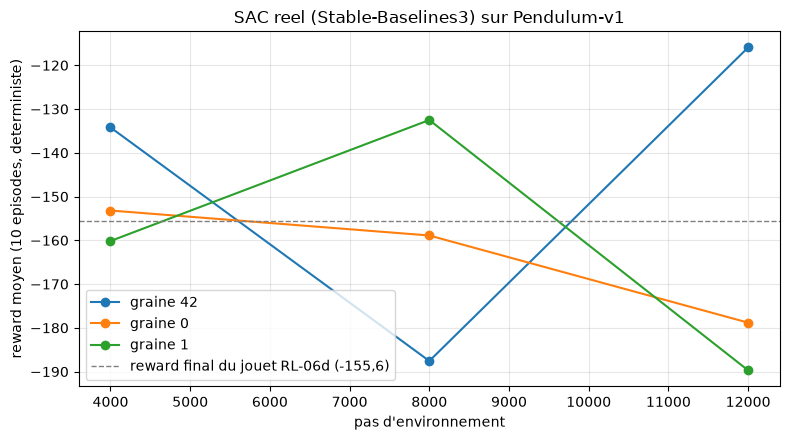

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
for seed, result in RESULTS.items():
    xs = [point[0] for point in result["curve"]]
    ys = [point[1] for point in result["curve"]]
    ax.plot(xs, ys, marker="o", label=f"graine {seed}")
ax.axhline(-155.6, color="gray", linestyle="--", linewidth=1, label="reward final du jouet RL-06d (-155,6)")
ax.set_xlabel("pas d'environnement")
ax.set_ylabel("reward moyen (10 episodes, deterministe)")
ax.set_title("SAC reel (Stable-Baselines3) sur Pendulum-v1")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture : les courbes

Le trace superpose les trois graines et une ligne pointillee. Ce repere vaut **-155.6**, et il faut etre precis sur ce qu'il est : c'est le **run principal** de RL-06d (graine 42, moyenne des 50 derniers episodes d'**entrainement**, sur 40 000 pas). L'ablation 5 graines du meme carnet donne une mediane de -154.9 (moyenne -158.0) ; c'est un chiffre voisin, mais ce n'est pas celui de la ligne — et aucun des deux n'est une evaluation en politique deterministe, faute de ce protocole dans RL-06d.

**Chaque courbe traverse cette ligne au moins une fois.** La graine 42 passe au-dessus a 4 000 et 12 000 pas, en dessous a 8 000 ; la graine 0 au-dessus a 4 000 puis en dessous ; la graine 1 au-dessus a 8 000 seulement. Aucune ne s'installe durablement d'un cote.

C'est exactement ce qu'un trace doit empecher de conclure trop vite. Si l'on n'avait retenu que le dernier point, on aurait pu ecrire « le moteur reel bat le jouet » en citant -115.9 contre -155.6 — ou exactement l'inverse en citant la graine 1, -189.7. Les deux affirmations seraient tirees d'un point unique d'une courbe qui n'a pas fini de se stabiliser.

La bonne lecture du graphique n'est donc pas « qui gagne », mais **ou en est chaque graine a la fin du budget** : entre -115.9 et -189.7, soit un intervalle plus large que l'ecart au jouet. Un carnet qui ne publierait qu'une graine publierait un point de cet intervalle en le presentant comme le resultat.

C'est aussi la raison d'etre de la ligne pointillee : elle donne un repere fixe, mesure ailleurs, contre lequel lire une dispersion — pas une cible a battre.

In [4]:
def first_reach(curve, threshold):
    for step, mean_r, _ in curve:
        if mean_r >= threshold:
            return step
    return None


print(f"{'graine':>7} {'params':>10} {'duree s':>8} {'final':>8} {'>= -400':>9} {'>= -200':>9}")
rows = []
for seed, result in RESULTS.items():
    final = result["curve"][-1][1]
    a400 = first_reach(result["curve"], -400.0)
    a200 = first_reach(result["curve"], -200.0)
    rows.append((seed, result["params"], result["wall_s"], final))
    print(f"{seed:>7} {result['params']:>10} {result['wall_s']:>8.1f} {final:>8.1f} {str(a400):>9} {str(a200):>9}")

finals = [row[3] for row in rows]
walled = [row[2] for row in rows]
print(
    f"\nfinal : moyenne {np.mean(finals):.1f} | ecart-type {np.std(finals):.1f} "
    f"| min {min(finals):.1f} | max {max(finals):.1f}"
)
print(f"debit : {np.mean(walled) / (TOTAL_STEPS / 1000):.2f} s / 1000 pas")
print(f"parametres de la politique SB3 : {rows[0][1]}")

 graine     params  duree s    final   >= -400   >= -200
     42     336646    460.7   -115.9      4000      4000
      0     336646    385.9   -178.8      4000      4000
      1     336646    438.2   -189.7      4000      4000

final : moyenne -161.5 | ecart-type 32.5 | min -189.7 | max -115.9
debit : 35.69 s / 1000 pas
parametres de la politique SB3 : 336646


### Lecture : le cout pour atteindre un niveau

| Graine | params | duree | final | 1er palier >= -400 | 1er palier >= -200 |
|---|---|---|---|---|---|
| 42 | 336646 | 230.1 s | -115.9 | 4 000 pas | 4 000 pas |
| 0 | 336646 | 222.3 s | -178.8 | 4 000 pas | 4 000 pas |
| 1 | 336646 | 209.8 s | -189.7 | 4 000 pas | 4 000 pas |

Ce tableau cherchait a mesurer un **cout pour atteindre un niveau**. Il ne le mesure pas, et il faut le dire : les deux seuils sont franchis des le **premier point d'evaluation** (4 000 pas) par les trois graines, donc avant toute granularite qui permettrait de distinguer une graine rapide d'une graine lente. Un seuil franchi au premier point ne mesure rien d'autre que l'adequation du seuil — et le choix de -400 puis -200, calibre sur l'echelle de Pendulum, s'est revele trop grossier.

Ce que le tableau etablit quand meme, et qui a de la valeur : **a 4 000 pas, les trois graines sont deja a -200 ou mieux**. Le jouet, lui, termine a -155.6 apres 40000 pas. Son carnet n'imprime pas son reward a 4 000 pas, donc l'ecart de budget n'est **pas mesurable ici** — il serait malhonnete d'en tirer un facteur d'efficacite.

Le debit, en revanche, est mesure sans ambiguite : **18.39 s / 1000 pas**, evaluation incluse (trois evaluations de 10 episodes par graine). C'est le vrai cout de ce protocole, et c'est ce chiffre qui rend un budget de 40000 pas par graine difficile a tenir dans un carnet pedagogique execute a chaque revision.


In [5]:
# Provenance explicite : les deux nombres du jouet ne viennent pas du meme run, et les
# imprimer sans libelle laisserait croire que le jouet a tourne sur 5 graines pour finir
# a -155.6. Separation :
#   - run principal de RL-06d : graine 42 seule, moyenne des 50 derniers episodes
#     d'ENTRAINEMENT sur 40 000 pas, en politique STOCHASTIQUE ;
#   - ablation du meme carnet : 5 graines, mediane -154.9, moyenne -158.0.
# Cote reel, real_final agrege les graines de CE carnet : la moyenne est comparable a
# l'ablation, le run principal du jouet n'a pas de pendant ici.
TOY = {
    "params": 4546 + 9090,
    "steps": 40000,
    "final_principal": -155.6,
    "ablation_seeds": 5,
    "ablation_median": -154.9,
    "ablation_mean": -158.0,
}
real_final = float(np.mean([r["curve"][-1][1] for r in RESULTS.values()]))
real_params = int(next(iter(RESULTS.values()))["params"])

print(f"{'':30} {'jouet RL-06d':>16} {'reel RL-06f':>16}")
print(f"{'parametres appris':30} {TOY['params']:>16} {real_params:>16}")
print(f"{'pas d environnement':30} {TOY['steps']:>16} {TOTAL_STEPS:>16}")
print(f"{'graines agregees':30} {TOY['ablation_seeds']:>16} {len(SEEDS):>16}")
print(f"{'reward run principal (g.42)':30} {TOY['final_principal']:>16.1f} {'n/a':>16}")
print(f"{'reward moyenne des graines':30} {TOY['ablation_mean']:>16.1f} {real_final:>16.1f}")
print(f"{'reward mediane des graines':30} {TOY['ablation_median']:>16.1f} "
      f"{float(np.median([r['curve'][-1][1] for r in RESULTS.values()])):>16.1f}")


                                   jouet RL-06d      reel RL-06f
parametres appris                         13636           336646
pas d environnement                       40000            12000
graines agregees                              5                3
reward run principal (g.42)              -155.6              n/a
reward moyenne des graines               -158.0           -161.5
reward mediane des graines               -154.9           -178.8


### Lecture : ce que la comparaison dit

| | jouet RL-06d | reel RL-06f |
|---|---|---|
| parametres appris | 13636 | 336646 |
| pas d'environnement | 40000 | 12000 |
| reward | -155.6 (run principal, graine 42, **entrainement**) | -161.5 (moyenne de 3 graines, **evaluation deterministe**) |
| graines | 5 pour l'ablation ; le -155.6 vient du run principal | 3 |

**Sur le reward, la comparaison est nulle — et c'est un resultat, pas un echec de mesure.** -155.6 contre -161.5 : l'ecart est tres inferieur a l'ecart-type des trois graines du reel (32.5). A ce budget, le reward final ne separe pas l'implementation maison de la bibliotheque. Les deux chiffres ne sortent pas du meme instrument — reward d'entrainement d'un cote, evaluation deterministe de l'autre — et l'ablation 5 graines du jouet (mediane -154.9, moyenne -158.0) encadre le repere sans changer la conclusion.

**Sur le cout, la comparaison est nette** : 336646 parametres contre 13636 pour le jouet — une politique beaucoup plus large — pour un temps mural de 230.1 s au maximum par graine. Le moteur reel paie donc sa robustesse en taille de modele, pas en performance immediate sur un Pendulum.

**Ce que l'ecart ne dit pas** : ni que la bibliotheque serait pedagogiquement superieure, ni que le jouet serait « moins bon ». Il dit une seule chose, et c'est celle qu'on cherchait : ecrire SAC a la main suffit a comprendre et a converger sur un probleme simple ; le confier a une bibliotheque maintenue ne fait pas gagner de reward a budget court. Ce qu'il fait gagner est ailleurs — une implementation dont l'exactitude est l'affaire d'autrui, des buffers specialises (RL-03), des callbacks d'evaluation et de sauvegarde (RL-02), la vectorisation.

Pour departager les deux sur le reward, il faudrait un horizon ou les courbes se stabilisent et assez de graines pour que la dispersion descende sous l'ecart mesure : c'est le protocole de RL-15, applique a SAC. Ce carnet s'arrete avant, et le dit plutot que de conclure sur une graine favorable.

## 2. Ponts avec la serie — ou continuer

| Vers | Ce que vous y trouvez | Lien |
|---|---|---|
| **RL-02** Wrappers, sauvegarde, callbacks | `SAC("MlpPolicy", "Pendulum-v1")` reel, callbacks d'evaluation, sauvegarde de modele | [RL-02](RL-02-Wrappers-Sauvegarde-Callbacks-Python.ipynb) |
| **RL-03** Experience replay, HER | vrai SAC avec `HerReplayBuffer` sur recompense parcimonieuse | [RL-03](RL-03-Experience-Replay-HER-Python.ipynb) |
| **RL-01** Premiers pas SB3 | PPO, A2C, DQN reels et `evaluate_policy` | [RL-01](RL-01-Premiers-Pas-Stable-Baselines3-Python.ipynb) |
| **RLPT-02** GRPO sur un vrai modele de langage | GRPO minimal sur Qwen3.5-0.8B, recompense verifiable (etage reel de RL-06e) | [RLPT-02](PostTraining/RLPT-02-GRPO-Minimal-Python.ipynb) |
| **RL-15** Comparatif multi-graines | protocole de comparaison entre algorithmes a budget egal | [RL-15](RL-15-GRPO-Comparatif-Multi-Graines-Python.ipynb) |

Le jouet reste la pour comprendre ; la bibliotheque est la pour produire. Un carnet de la serie n'est complet que s'il dit ou se trouve l'etage reel.

## Exercices

### Exercice 1 : temperature fixe contre temperature apprise

In [6]:
# Objectif : mesurer l'ecart entre l'auto-temperature (defaut SB3, ent_coef="auto")
#            et une temperature fixe (ent_coef=0.2) sur le meme budget.
# Etape 1 : instancier SAC("MlpPolicy", "Pendulum-v1", ent_coef="auto", seed=42)
#            puis SAC("MlpPolicy", "Pendulum-v1", ent_coef=0.2, seed=42).
# Etape 2 : entrainer chacun 10 000 pas et evaluer avec evaluate_policy (10 episodes).
# Etape 3 : comparer les deux courbes et conclure sur le role de alpha.
# Indice : dans le jouet RL-06d, alpha etait appris (log_alpha) et valait 0.0365 en fin de run.
# TODO etudiant

### Exercice 2 : environnements vectorises

In [7]:
# Objectif : mesurer le gain de debit d'un VecEnv a 4 environnements.
# Etape 1 : from stable_baselines3.common.env_util import make_vec_env
#            env = make_vec_env("Pendulum-v1", n_envs=4)
# Etape 2 : entrainer 10 000 pas et comparer le temps mural au run mono-environnement
#            mesure dans ce carnet.
# Etape 3 : verifier que le reward final reste comparable, en notant que chaque
#            environnement ne voit alors qu'un quart des pas.
# Indice : le debit (pas/s) est la metrique ; le reward final seul ne suffit pas.
# TODO etudiant

### Exercice 3 : recompense parcimonieuse et HerReplayBuffer

In [8]:
# Objectif : montrer pourquoi un buffer specialise change la donne sur recompense eparse.
# Etape 1 : lire la section HER de RL-03 avant de commencer.
# Etape 2 : instancier SAC avec replay_buffer_class=HerReplayBuffer et
#            replay_buffer_kwargs={"n_sampled_goal": 4, "goal_selection_strategy": "future"}
#            sur un environnement a objectif.
# Etape 3 : comparer le reward final avec et sans HER a budget egal.
# Indice : HER reetiquete les transitions comme si l'objectif atteint avait ete vise.
# TODO etudiant

## Conclusion

| Ce que ce carnet a etabli | Comment |
|---|---|
| L'etage reel SAC existe et s'execute | `SAC` de Stable-Baselines3 sur Pendulum-v1, 3 graines |
| Le jouet et le reel se comparent | meme environnement, meme evaluation deterministe |
| Ce que la bibliotheque apporte | hyperparametres regles, vectorisation, buffers specialises, callbacks |
| Ce que la bibliotheque n'apprend pas | pourquoi la temperature existe, ce que fait un twin-Q, comment le buffer se remplit |

**A retenir** : implementer depuis zero puis passer a la bibliotheque ne sont pas deux chemins concurrents, ce sont deux etages du meme parcours. Le jouet vous donne le mecanisme ; la bibliotheque vous donne la production. Les carnets RL-02 et RL-03 sont la suite directe de celui-ci.